In [ ]:

import os

DRIVE_ROOT = "/content/drive/MyDrive"

print("===== Google Drive 폴더 확인 =====")

if os.path.exists(DRIVE_ROOT):
    print("MyDrive 연결 성공!")
    print("\nMyDrive 안의 파일 및 폴더:")

    for item in os.listdir(DRIVE_ROOT):
        print("📁" if os.path.isdir(os.path.join(DRIVE_ROOT, item)) else "📄", item)
else:
    print("MyDrive 경로가 없습니다.")

# fer2013-data 폴더 검색 (최대 5단계)
matches = []

for root, dirs, files in os.walk(DRIVE_ROOT):
    depth = root.replace(DRIVE_ROOT, "").count(os.sep)

    dirs[:] = [
        d for d in dirs
        if d not in [".trash", ".shortcut-targets-by-id"]
    ]

    if depth >= 5:
        dirs[:] = []

    for d in dirs:
        if d.lower() == "fer2013_data":
            matches.append(os.path.join(root, d))

print("\n===== 데이터셋 검색 결과 =====")

if matches:
    for path in matches:
        print("찾았습니다:", path)
        print("내용:", os.listdir(path))
else:
    print("fer2013-data 폴더를 찾지 못했습니다.")


===== Google Drive 폴더 확인 =====
MyDrive 연결 성공!

MyDrive 안의 파일 및 폴더:
📄 inbound6492310352399817715.jpg
📁 Colab Notebooks
📁 Classroom
📁 Saved from the Google app
📄 IMG_6054.jpeg
📄 IMG_6484.jpeg
📄 IMG_6490.jpeg
📁 fer2013_data

===== 데이터셋 검색 결과 =====
찾았습니다: /content/drive/MyDrive/fer2013_data
내용: ['test', 'train']


In [ ]:

import os
import shutil

DRIVE_DATA_ROOT = "/content/drive/MyDrive/fer2013_data"
LOCAL_DATA_ROOT = "/content/fer2013_data"

# Check Google Drive folder
assert os.path.isdir(DRIVE_DATA_ROOT), "Dataset folder not found!"

# Check train and test
assert os.path.isdir(os.path.join(DRIVE_DATA_ROOT, "train"))
assert os.path.isdir(os.path.join(DRIVE_DATA_ROOT, "test"))

# Copy to Colab local storage
if os.path.exists(LOCAL_DATA_ROOT):
    shutil.rmtree(LOCAL_DATA_ROOT)

shutil.copytree(DRIVE_DATA_ROOT, LOCAL_DATA_ROOT)

# Update dataset path
DATA_ROOT = LOCAL_DATA_ROOT

print("Dataset connected successfully!")
print("Dataset path:", DATA_ROOT)
print("Train classes:", os.listdir(os.path.join(DATA_ROOT, "train")))
print("Test classes:", os.listdir(os.path.join(DATA_ROOT, "test")))


Dataset connected successfully!
Dataset path: /content/fer2013_data
Train classes: ['disgust', 'fear', 'happy', 'surprise', 'angry', 'sad', 'neutral']
Test classes: ['disgust', 'fear', 'happy', 'surprise', 'angry', 'sad', 'neutral']


In [ ]:

import os
import numpy as np
from sklearn.model_selection import train_test_split

SEED = 42
TARGET_TRAIN_SIZE = 8000

train_dir = os.path.join(DATA_ROOT, "train")
test_dir = os.path.join(DATA_ROOT, "test")

class_names = sorted([
    d for d in os.listdir(train_dir)
    if os.path.isdir(os.path.join(train_dir, d))
])

print("Classes:", class_names)

# Collect image paths and labels
image_extensions = (".jpg", ".jpeg", ".png", ".bmp")

image_paths = []
labels = []

for label, class_name in enumerate(class_names):
    folder = os.path.join(train_dir, class_name)

    files = sorted([
        os.path.join(folder, f)
        for f in os.listdir(folder)
        if f.lower().endswith(image_extensions)
    ])

    image_paths.extend(files)
    labels.extend([label] * len(files))

image_paths = np.array(image_paths)
labels = np.array(labels)

print("\nOriginal training images:", len(image_paths))

# Select 8,000 images with stratified sampling
if len(image_paths) > TARGET_TRAIN_SIZE:
    image_paths, _, labels, _ = train_test_split(
        image_paths,
        labels,
        train_size=TARGET_TRAIN_SIZE,
        random_state=SEED,
        stratify=labels
    )

print("\nReduced training images:", len(image_paths))

print("\nClass distribution:")
for i, name in enumerate(class_names):
    print(name, ":", np.sum(labels == i))

assert len(image_paths) == min(TARGET_TRAIN_SIZE, len(image_paths)) or len(image_paths) == TARGET_TRAIN_SIZE

print("\n8,000 image selection completed!")


Classes: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']

Original training images: 28775

Reduced training images: 8000

Class distribution:
angry : 1111
disgust : 121
fear : 1144
happy : 2011
neutral : 1380
sad : 1352
surprise : 881

8,000 image selection completed!


In [ ]:

from PIL import Image
import numpy as np
from sklearn.model_selection import train_test_split

# Load selected 8,000 images
X = []
y = []

for path, label in zip(image_paths, labels):
    img = Image.open(path).convert("L")
    img = img.resize((48, 48))

    X.append(np.array(img))
    y.append(label)

X = np.array(X, dtype=np.float32)
y = np.array(y, dtype=np.int64)

# Normalize pixel values (0~1)
X = X / 255.0

# Add channel dimension
X = X.reshape(-1, 48, 48, 1)

print("Image shape:", X.shape)
print("Label shape:", y.shape)
print("Pixel range:", X.min(), "~", X.max())

# Split Train and Validation
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.15,
    random_state=42,
    stratify=y
)

print("\nTraining:", X_train.shape)
print("Validation:", X_val.shape)
print("Preprocessing completed!")


Image shape: (8000, 48, 48, 1)
Label shape: (8000,)
Pixel range: 0.0 ~ 1.0

Training: (6800, 48, 48, 1)
Validation: (1200, 48, 48, 1)
Preprocessing completed!


In [ ]:

# ==========================================
# STEP 5: Load Test Dataset
# ==========================================

import os
import numpy as np
from PIL import Image

test_dir = os.path.join(DATA_ROOT, "test")

X_test_list = []
y_test_list = []

image_extensions = (".jpg", ".jpeg", ".png", ".bmp")

for label, class_name in enumerate(class_names):

    folder = os.path.join(test_dir, class_name)

    if not os.path.isdir(folder):
        raise FileNotFoundError(f"Missing test class: {folder}")

    for filename in sorted(os.listdir(folder)):

        if filename.lower().endswith(image_extensions):

            path = os.path.join(folder, filename)

            try:
                img = Image.open(path).convert("L")
                img = img.resize((48, 48))

                X_test_list.append(np.array(img))
                y_test_list.append(label)

            except Exception as e:
                print("Image error:", path, e)

X_test = np.array(X_test_list, dtype=np.float32)
X_test = X_test / 255.0
X_test = X_test.reshape(-1, 48, 48, 1)

y_test = np.array(y_test_list, dtype=np.int64)

print("Test images:", X_test.shape)
print("Test labels:", y_test.shape)
print("Test classes:", class_names)

assert len(X_test) > 0
assert len(X_test) == len(y_test)

print("Test dataset loading completed!")


Test images: (7178, 48, 48, 1)
Test labels: (7178,)
Test classes: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Test dataset loading completed!


In [ ]:

# ==========================================
# STEP 6: Class Weight
# ==========================================

from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(y_train)

class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = {
    int(c): float(w)
    for c, w in zip(classes, class_weights_array)
}

print("Class Weights:")

for i, name in enumerate(class_names):
    print(f"{name}: {class_weights[i]:.4f}")


Class Weights:
angry: 1.0291
disgust: 9.4313
fear: 0.9984
happy: 0.5684
neutral: 0.8282
sad: 0.8455
surprise: 1.2970


In [ ]:

# ==========================================
# STEP 7: Training Configuration
# ==========================================

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
EPOCHS = 15
BATCH_SIZE = 64

tf.random.set_seed(SEED)
np.random.seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

print("\nTrain:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

print("\nEpochs:", EPOCHS)
print("Batch size:", BATCH_SIZE)


TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

Train: (6800, 48, 48, 1)
Validation: (1200, 48, 48, 1)
Test: (7178, 48, 48, 1)

Epochs: 15
Batch size: 64


In [ ]:

# ==========================================
# STEP 8: Baseline CNN
# ==========================================

def build_baseline(num_classes):

    inputs = keras.Input(shape=(48, 48, 1))

    x = layers.Conv2D(
        32, 3, padding="same", activation="relu"
    )(inputs)

    x = layers.MaxPooling2D()(x)

    x = layers.Conv2D(
        64, 3, padding="same", activation="relu"
    )(x)

    x = layers.MaxPooling2D()(x)

    x = layers.Flatten()(x)

    x = layers.Dense(128, activation="relu")(x)

    outputs = layers.Dense(
        num_classes, activation="softmax"
    )(x)

    model = keras.Model(
        inputs, outputs, name="baseline_cnn"
    )

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


baseline = build_baseline(len(class_names))

baseline.summary()


Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 48, 48, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,179,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,199,495 (4.58 MB)

 Trainable params: 1,199,495 (4.58 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:

# ==========================================
# STEP 8-2: Train Baseline CNN
# ==========================================

def make_callbacks(model_name):

    return [
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=4,
            restore_best_weights=True
        ),

        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=2,
            min_lr=1e-6
        ),

        keras.callbacks.ModelCheckpoint(
            f"/content/{model_name}_best.keras",
            monitor="val_loss",
            save_best_only=True
        )
    ]


history1 = baseline.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    class_weight=class_weights,
    callbacks=make_callbacks("baseline"),
    verbose=1
)

print("Baseline CNN training completed!")


Epoch 1/15
107/107 ━━━━━━━━━━━━━━━━━━━━ 17s 85ms/step - accuracy: 0.1432 - loss: 1.9650 - val_accuracy: 0.1692 - val_loss: 1.9126 - learning_rate: 0.0010
Epoch 2/15
107/107 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.1888 - loss: 1.8927 - val_accuracy: 0.2333 - val_loss: 1.8489 - learning_rate: 0.0010
Epoch 3/15
107/107 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.2660 - loss: 1.7959 - val_accuracy: 0.3142 - val_loss: 1.7294 - learning_rate: 0.0010
Epoch 4/15
107/107 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.3326 - loss: 1.6858 - val_accuracy: 0.3367 - val_loss: 1.7081 - learning_rate: 0.0010
Epoch 5/15
107/107 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.3791 - loss: 1.5903 - val_accuracy: 0.3525 - val_loss: 1.6779 - learning_rate: 0.0010
Epoch 6/15
107/107 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.4171 - loss: 1.4731 - val_accuracy: 0.3708 - val_loss: 1.6469 - learning_rate: 0.0010
Epoch 7/15
107/107 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.4616 - loss: 1.3538

In [ ]:

# ==========================================
# STEP 9: Data Augmentation
# ==========================================

augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.10),
    layers.RandomTranslation(0.05, 0.05)
], name="data_augmentation")


# ==========================================
# STEP 9-2: Improved CNN
# ==========================================

def build_improved(num_classes):

    inputs = keras.Input(shape=(48, 48, 1))

    x = augmentation(inputs)

    # Block 1
    x = layers.Conv2D(
        32, 3, padding="same", use_bias=False
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    x = layers.Conv2D(
        32, 3, padding="same", use_bias=False
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    x = layers.MaxPooling2D()(x)
    x = layers.Dropout(0.25)(x)

    # Block 2
    x = layers.Conv2D(
        64, 3, padding="same", use_bias=False
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    x = layers.Conv2D(
        64, 3, padding="same", use_bias=False
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    x = layers.MaxPooling2D()(x)
    x = layers.Dropout(0.30)(x)

    # Block 3
    x = layers.Conv2D(
        128, 3, padding="same", activation="relu"
    )(x)

    x = layers.GlobalAveragePooling2D()(x)

    x = layers.Dense(128, activation="relu")(x)

    x = layers.Dropout(0.40)(x)

    outputs = layers.Dense(
        num_classes, activation="softmax"
    )(x)

    model = keras.Model(
        inputs, outputs, name="improved_cnn"
    )

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=5e-4
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


improved = build_improved(len(class_names))

improved.summary()


Model: "improved_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 48, 48, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 48, 48, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 24, 24, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 24, 24, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 156,839 (612.65 KB)

 Trainable params: 156,455 (611.15 KB)

 Non-trainable params: 384 (1.50 KB)

In [ ]:

# ==========================================
# STEP 10: Train Improved CNN
# ==========================================

history2 = improved.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    class_weight=class_weights,
    callbacks=make_callbacks("improved"),
    verbose=1
)

print("Improved CNN training completed!")


Epoch 1/15
107/107 ━━━━━━━━━━━━━━━━━━━━ 13s 37ms/step - accuracy: 0.1646 - loss: 1.9498 - val_accuracy: 0.1717 - val_loss: 1.9353 - learning_rate: 5.0000e-04
Epoch 2/15
107/107 ━━━━━━━━━━━━━━━━━━━━ 3s 27ms/step - accuracy: 0.1838 - loss: 1.9233 - val_accuracy: 0.2525 - val_loss: 1.9361 - learning_rate: 5.0000e-04
Epoch 3/15
107/107 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - accuracy: 0.1899 - loss: 1.9135 - val_accuracy: 0.2475 - val_loss: 1.9322 - learning_rate: 5.0000e-04
Epoch 4/15
107/107 ━━━━━━━━━━━━━━━━━━━━ 3s 29ms/step - accuracy: 0.1879 - loss: 1.9048 - val_accuracy: 0.1142 - val_loss: 1.9158 - learning_rate: 5.0000e-04
Epoch 5/15
107/107 ━━━━━━━━━━━━━━━━━━━━ 3s 27ms/step - accuracy: 0.1943 - loss: 1.9027 - val_accuracy: 0.1475 - val_loss: 1.9926 - learning_rate: 5.0000e-04
Epoch 6/15
107/107 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step - accuracy: 0.1910 - loss: 1.9018 - val_accuracy: 0.1875 - val_loss: 1.8871 - learning_rate: 5.0000e-04
Epoch 7/15
107/107 ━━━━━━━━━━━━━━━━━━━━ 4s 35ms/step - ac

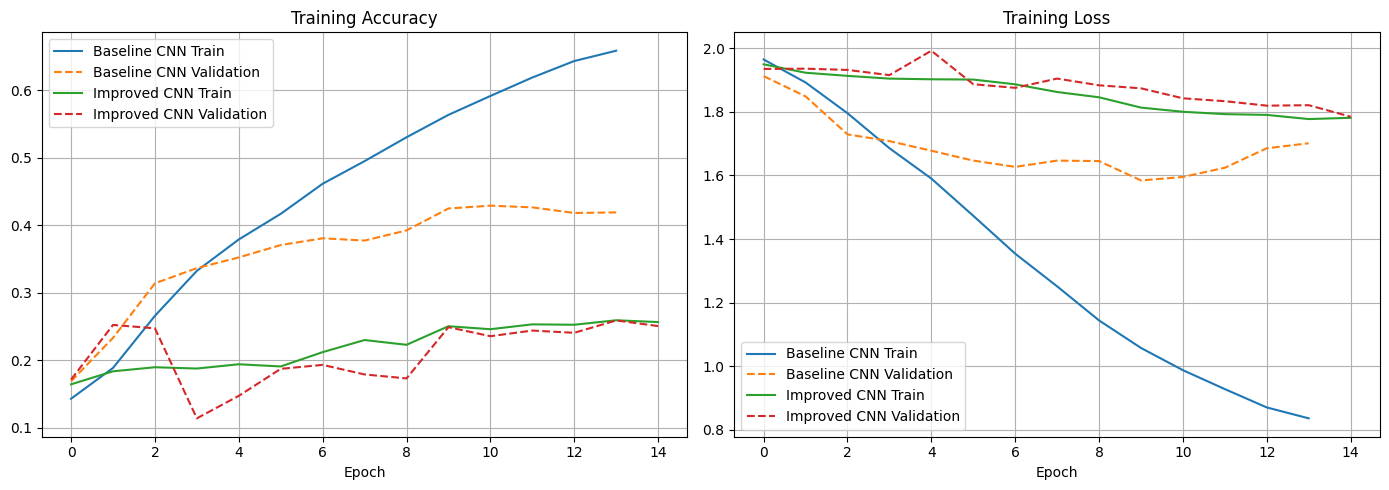

In [ ]:

# ==========================================
# STEP 11: Plot Training History
# ==========================================

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for hist, name in [
    (history1, "Baseline CNN"),
    (history2, "Improved CNN")
]:

    axes[0].plot(
        hist.history["accuracy"],
        label=f"{name} Train"
    )

    axes[0].plot(
        hist.history["val_accuracy"],
        linestyle="--",
        label=f"{name} Validation"
    )

    axes[1].plot(
        hist.history["loss"],
        label=f"{name} Train"
    )

    axes[1].plot(
        hist.history["val_loss"],
        linestyle="--",
        label=f"{name} Validation"
    )


axes[0].set_title("Training Accuracy")
axes[1].set_title("Training Loss")

for ax in axes:
    ax.set_xlabel("Epoch")
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()


In [ ]:
import pandas as pd
import numpy as np

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Libraries loaded successfully!")

Pandas: 2.2.3
NumPy: 2.4.6
Libraries loaded successfully!


In [ ]:

# ==========================================
# STEP 12: Model Evaluation
# ==========================================

from sklearn.metrics import accuracy_score, f1_score

def evaluate_model(model, X, y, name):

    probabilities = model.predict(
        X,
        batch_size=128,
        verbose=1
    )

    predictions = np.argmax(probabilities, axis=1)

    accuracy = accuracy_score(y, predictions)

    macro_f1 = f1_score(
        y,
        predictions,
        average="macro"
    )

    return {
        "model": name,
        "accuracy": accuracy,
        "macro_f1": macro_f1,
        "predictions": predictions,
        "probabilities": probabilities
    }


res1 = evaluate_model(
    baseline, X_test, y_test, "Baseline CNN"
)

res2 = evaluate_model(
    improved, X_test, y_test, "Improved CNN"
)

comparison = pd.DataFrame([
    {
        "Model": res1["model"],
        "Test Accuracy": res1["accuracy"],
        "Test Macro F1": res1["macro_f1"]
    },
    {
        "Model": res2["model"],
        "Test Accuracy": res2["accuracy"],
        "Test Macro F1": res2["macro_f1"]
    }
])

print("\n===== MODEL COMPARISON =====")
display(comparison)


57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step

===== MODEL COMPARISON =====


,Model,Test Accuracy,Test Macro F1
0,Baseline CNN,0.424213,0.387271
1,Improved CNN,0.250488,0.209231


In [ ]:

# ==========================================
# STEP 13: Select Best Model
# ==========================================

val1_predictions = np.argmax(
    baseline.predict(X_val, verbose=0),
    axis=1
)

val2_predictions = np.argmax(
    improved.predict(X_val, verbose=0),
    axis=1
)

val1 = f1_score(
    y_val, val1_predictions, average="macro"
)

val2 = f1_score(
    y_val, val2_predictions, average="macro"
)

if val2 >= val1:
    best_model = improved
    best_name = "Improved CNN"
    best_result = res2
else:
    best_model = baseline
    best_name = "Baseline CNN"
    best_result = res1

print("Baseline Validation Macro F1:", val1)
print("Improved Validation Macro F1:", val2)

print("\nSelected Model:", best_name)


Baseline Validation Macro F1: 0.3684297715412228
Improved Validation Macro F1: 0.20315154143707922

Selected Model: Baseline CNN


In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

print("Seaborn and Matplotlib imported successfully!")

Seaborn and Matplotlib imported successfully!


Selected Model: Baseline CNN
              precision    recall  f1-score   support

       angry       0.28      0.28      0.28       958
     disgust       0.23      0.32      0.26       111
        fear       0.28      0.23      0.25      1024
       happy       0.63      0.60      0.61      1774
     neutral       0.38      0.48      0.43      1233
         sad       0.34      0.30      0.32      1247
    surprise       0.55      0.58      0.56       831

    accuracy                           0.42      7178
   macro avg       0.38      0.40      0.39      7178
weighted avg       0.42      0.42      0.42      7178



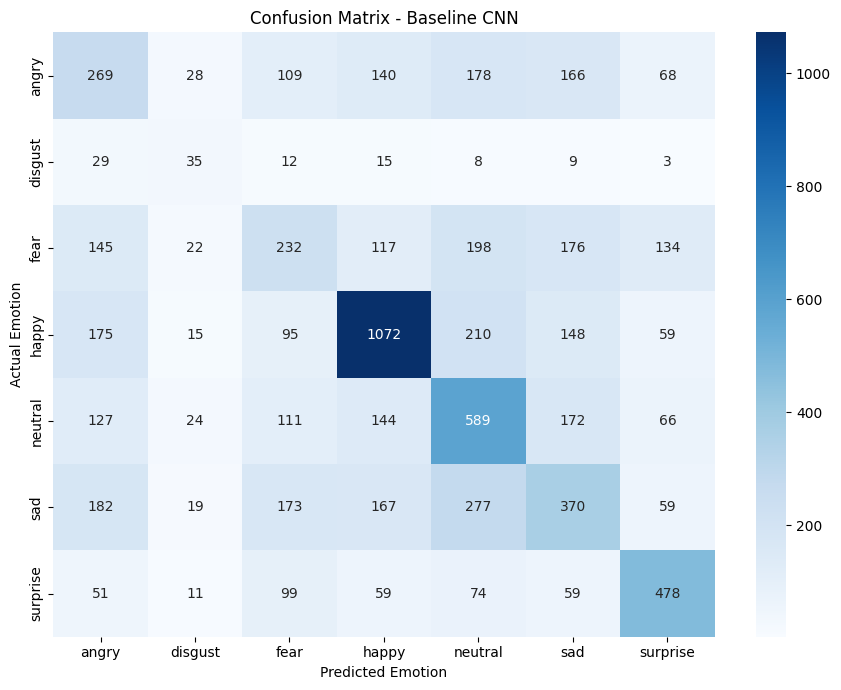

In [ ]:

# ==========================================
# STEP 14: Classification Report
# ==========================================

from sklearn.metrics import classification_report, confusion_matrix

y_pred = best_result["predictions"]

print("Selected Model:", best_name)

print(
    classification_report(
        y_test,
        y_pred,
        labels=list(range(len(class_names))),
        target_names=class_names,
        zero_division=0
    )
)

# Confusion Matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=list(range(len(class_names)))
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Emotion")
plt.ylabel("Actual Emotion")
plt.title(f"Confusion Matrix - {best_name}")

plt.tight_layout()
plt.show()


Incorrect predictions: 4133
Total test images: 7178


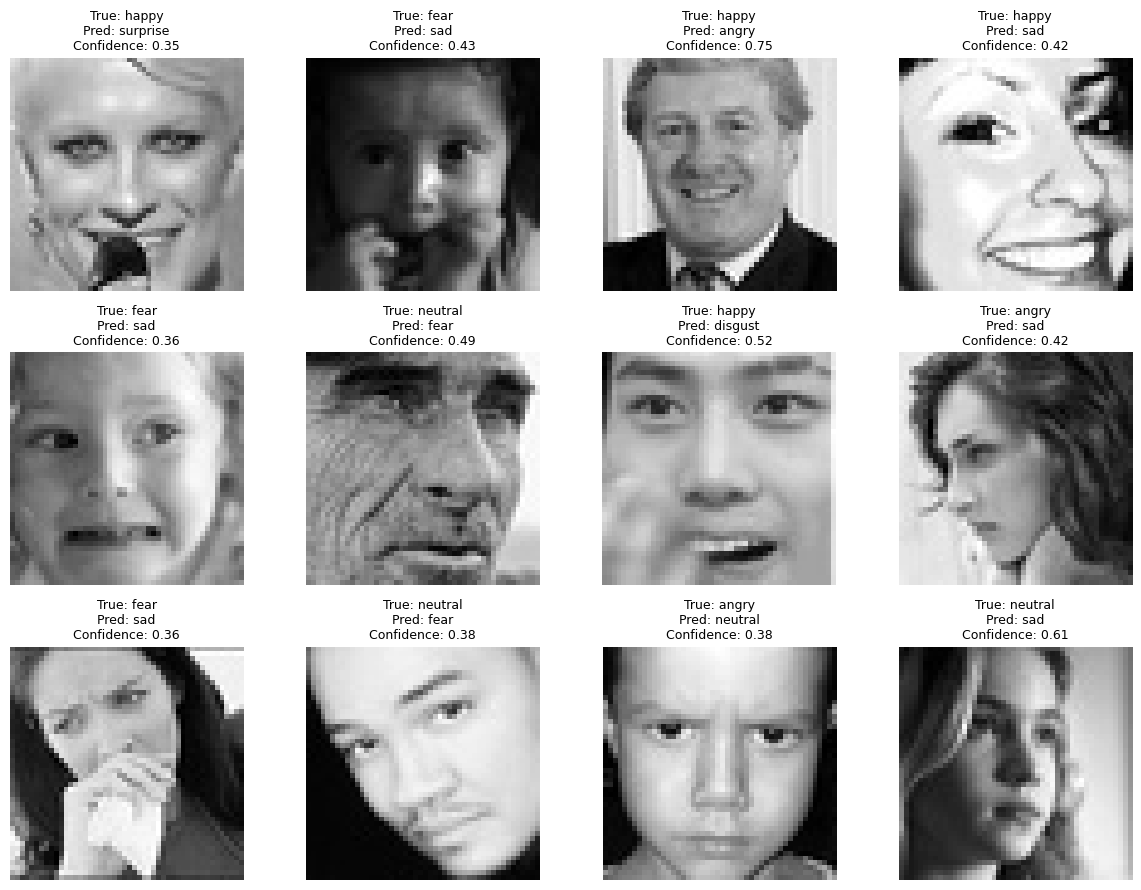

In [ ]:

# ==========================================
# STEP 15: Misclassified Images
# ==========================================

wrong = np.where(y_pred != y_test)[0]

print("Incorrect predictions:", len(wrong))
print("Total test images:", len(y_test))

if len(wrong) > 0:

    sample_wrong = np.random.choice(
        wrong,
        min(12, len(wrong)),
        replace=False
    )

    fig, axes = plt.subplots(
        3, 4, figsize=(12, 9)
    )

    for ax, idx in zip(axes.flat, sample_wrong):

        ax.imshow(
            X_test[idx].squeeze(),
            cmap="gray"
        )

        confidence = np.max(
            best_result["probabilities"][idx]
        )

        ax.set_title(
            f"True: {class_names[y_test[idx]]}\n"
            f"Pred: {class_names[y_pred[idx]]}\n"
            f"Confidence: {confidence:.2f}",
            fontsize=9
        )

        ax.axis("off")

    plt.tight_layout()
    plt.show()

else:
    print("No misclassified images.")


In [ ]:

# ==========================================
# STEP 16: Save Models and Results
# ==========================================

import os
import json
import pandas as pd
import shutil

OUTPUT_DIR = "/content/moodtune_output"

MODEL_DIR = os.path.join(OUTPUT_DIR, "models")
REPORT_DIR = os.path.join(OUTPUT_DIR, "reports")

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(REPORT_DIR, exist_ok=True)

# Save both CNN models
baseline.save(
    os.path.join(MODEL_DIR, "baseline_cnn.keras")
)

improved.save(
    os.path.join(MODEL_DIR, "improved_cnn.keras")
)

# Save selected model
best_model.save(
    os.path.join(MODEL_DIR, "emotion_model.keras")
)

# Save class names
with open(
    os.path.join(MODEL_DIR, "class_names.json"),
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        class_names,
        f,
        ensure_ascii=False,
        indent=4
    )

# Save model comparison
comparison.to_csv(
    os.path.join(REPORT_DIR, "model_comparison.csv"),
    index=False
)

# Save training summary
summary = {
    "project": "MoodTune AI",
    "selected_model": best_name,
    "train_samples": int(len(X_train)),
    "validation_samples": int(len(X_val)),
    "test_samples": int(len(X_test)),
    "number_of_classes": len(class_names),
    "class_names": class_names,
    "epochs_max": EPOCHS,
    "batch_size": BATCH_SIZE,
    "validation_macro_f1_baseline": float(val1),
    "validation_macro_f1_improved": float(val2),
    "test_accuracy": float(best_result["accuracy"]),
    "test_macro_f1": float(best_result["macro_f1"]),
    "random_seed": SEED
}

with open(
    os.path.join(REPORT_DIR, "training_summary.json"),
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        summary,
        f,
        ensure_ascii=False,
        indent=4
    )

print("All models and reports saved!")
print("Output:", OUTPUT_DIR)


All models and reports saved!
Output: /content/moodtune_output


In [ ]:

# ==========================================
# STEP 17: Backup to Google Drive
# ==========================================

DRIVE_OUTPUT = "/content/drive/MyDrive/MoodTune_AI_Results"

os.makedirs(DRIVE_OUTPUT, exist_ok=True)

# Create ZIP archive
ZIP_PATH = shutil.make_archive(
    "/content/MoodTune_AI_Results",
    "zip",
    OUTPUT_DIR
)

# Copy ZIP to Google Drive
DRIVE_ZIP = os.path.join(
    DRIVE_OUTPUT,
    "MoodTune_AI_Results.zip"
)

shutil.copy2(ZIP_PATH, DRIVE_ZIP)

# Also copy individual output folders
shutil.copytree(
    MODEL_DIR,
    os.path.join(DRIVE_OUTPUT, "models"),
    dirs_exist_ok=True
)

shutil.copytree(
    REPORT_DIR,
    os.path.join(DRIVE_OUTPUT, "reports"),
    dirs_exist_ok=True
)

print("================================")
print("MOODTUNE AI BACKUP COMPLETED!")
print("================================")

print("Google Drive location:")
print(DRIVE_OUTPUT)

print("\nZIP file:")
print(DRIVE_ZIP)


MOODTUNE AI BACKUP COMPLETED!
Google Drive location:
/content/drive/MyDrive/MoodTune_AI_Results

ZIP file:
/content/drive/MyDrive/MoodTune_AI_Results/MoodTune_AI_Results.zip


In [ ]:

# ==========================================
# STEP 18: Final Project Summary
# ==========================================

print("=" * 50)
print("          MOODTUNE AI PROJECT")
print("=" * 50)

print("\nDataset:")
print("Training images:", len(X_train))
print("Validation images:", len(X_val))
print("Test images:", len(X_test))

print("\nEmotion classes:")
for name in class_names:
    print("-", name)

print("\nModel Comparison:")
display(comparison)

print("\nBest Model:", best_name)

print("\nTest Accuracy:",
      round(best_result["accuracy"] * 100, 2), "%")

print("Test Macro F1:",
      round(best_result["macro_f1"], 4))

print("\nSaved to:")
print(DRIVE_OUTPUT)

print("\nMOODTUNE AI TRAINING FINISHED!")


          MOODTUNE AI PROJECT

Dataset:
Training images: 6800
Validation images: 1200
Test images: 7178

Emotion classes:
- angry
- disgust
- fear
- happy
- neutral
- sad
- surprise

Model Comparison:


,Model,Test Accuracy,Test Macro F1
0,Baseline CNN,0.424213,0.387271
1,Improved CNN,0.250488,0.209231



Best Model: Baseline CNN

Test Accuracy: 42.42 %
Test Macro F1: 0.3873

Saved to:
/content/drive/MyDrive/MoodTune_AI_Results

MOODTUNE AI TRAINING FINISHED!


In [ ]:

# ==========================================
# CELL 1: Check Analysis Environment
# ==========================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score
)

print("Checking MoodTune AI environment...")

required_variables = [
    "best_model",
    "X_test",
    "y_test",
    "class_names",
    "best_name"
]

for var in required_variables:
    if var not in globals():
        raise NameError(
            f"{var} is missing. "
            "Please restore the previous Colab variables."
        )

print("\nSelected Model:", best_name)
print("Test Images:", len(X_test))
print("Emotion Classes:", class_names)
print("Number of Classes:", len(class_names))

print("\nEnvironment check completed!")


Checking MoodTune AI environment...

Selected Model: Baseline CNN
Test Images: 7178
Emotion Classes: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Number of Classes: 7

Environment check completed!


In [ ]:

# ==========================================
# CELL 2: Generate Test Predictions
# ==========================================

# Convert data to NumPy arrays
X_test_analysis = np.asarray(X_test)
y_test_analysis = np.asarray(y_test).astype(int)

# Add channel dimension if necessary
if X_test_analysis.ndim == 3:
    X_test_analysis = np.expand_dims(
        X_test_analysis, axis=-1
    )

# Check model input shape
print("Model input shape:", best_model.input_shape)
print("Test input shape:", X_test_analysis.shape)

# Predict
y_prob = best_model.predict(
    X_test_analysis,
    batch_size=128,
    verbose=1
)

y_pred_analysis = np.argmax(y_prob, axis=1)

# Overall performance
accuracy = accuracy_score(
    y_test_analysis,
    y_pred_analysis
)

macro_f1 = f1_score(
    y_test_analysis,
    y_pred_analysis,
    average="macro"
)

print("\n===== TEST PERFORMANCE =====")
print(f"Accuracy: {accuracy * 100:.2f}%")
print(f"Macro F1: {macro_f1:.4f}")

print("\nPrediction completed!")


Model input shape: (None, 48, 48, 1)
Test input shape: (7178, 48, 48, 1)
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step

===== TEST PERFORMANCE =====
Accuracy: 42.42%
Macro F1: 0.3873

Prediction completed!


In [ ]:

# ==========================================
# CELL 3: Emotion Classification Report
# ==========================================

report = classification_report(
    y_test_analysis,
    y_pred_analysis,
    labels=list(range(len(class_names))),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

emotion_results = pd.DataFrame([
    {
        "Emotion": emotion,
        "Precision": report[emotion]["precision"],
        "Recall": report[emotion]["recall"],
        "F1-Score": report[emotion]["f1-score"],
        "Support": int(report[emotion]["support"])
    }
    for emotion in class_names
])

print("===== EMOTION-BY-EMOTION PERFORMANCE =====")

display(
    emotion_results.style.format({
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-Score": "{:.4f}",
        "Support": "{:,.0f}"
    })
)

print("\n===== FULL CLASSIFICATION REPORT =====")

print(
    classification_report(
        y_test_analysis,
        y_pred_analysis,
        labels=list(range(len(class_names))),
        target_names=class_names,
        zero_division=0
    )
)


===== EMOTION-BY-EMOTION PERFORMANCE =====


,Emotion,Precision,Recall,F1-Score,Support
0,angry,0.2751,0.2808,0.2779,958
1,disgust,0.2273,0.3153,0.2642,111
2,fear,0.2792,0.2266,0.2501,"1,024"
3,happy,0.6254,0.6043,0.6147,"1,774"
4,neutral,0.3840,0.4777,0.4257,"1,233"
5,sad,0.3364,0.2967,0.3153,"1,247"
6,surprise,0.5513,0.5752,0.5630,831



===== FULL CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

       angry       0.28      0.28      0.28       958
     disgust       0.23      0.32      0.26       111
        fear       0.28      0.23      0.25      1024
       happy       0.63      0.60      0.61      1774
     neutral       0.38      0.48      0.43      1233
         sad       0.34      0.30      0.32      1247
    surprise       0.55      0.58      0.56       831

    accuracy                           0.42      7178
   macro avg       0.38      0.40      0.39      7178
weighted avg       0.42      0.42      0.42      7178



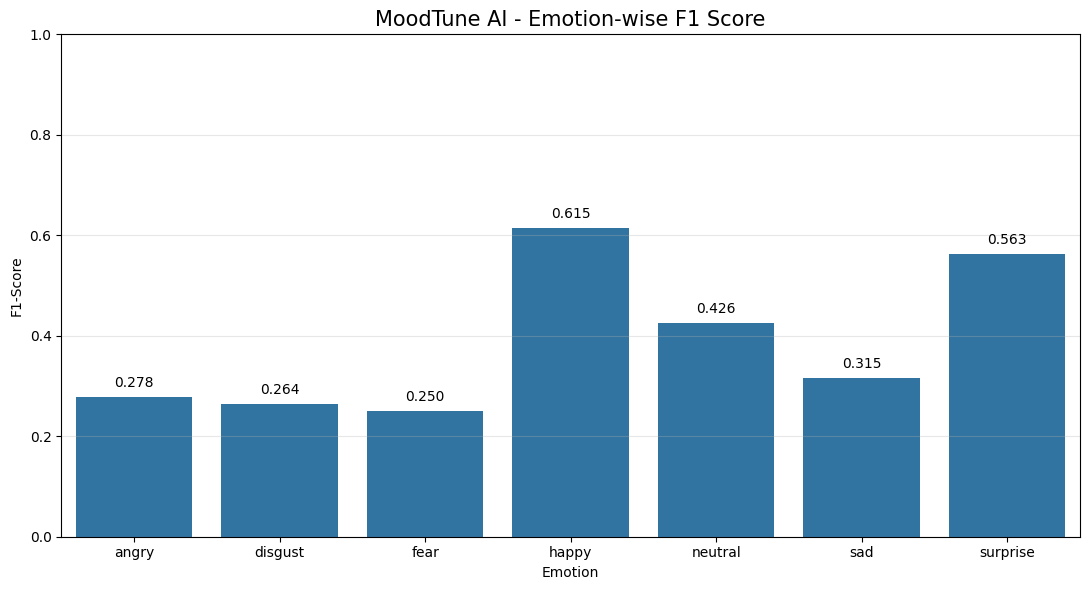

In [ ]:

# ==========================================
# CELL 4: Emotion F1-Score Visualization
# ==========================================

plt.figure(figsize=(11, 6))

sns.barplot(
    data=emotion_results,
    x="Emotion",
    y="F1-Score"
)

plt.title(
    "MoodTune AI - Emotion-wise F1 Score",
    fontsize=15
)

plt.xlabel("Emotion")
plt.ylabel("F1-Score")

plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)

for i, value in enumerate(
    emotion_results["F1-Score"]
):
    plt.text(
        i,
        value + 0.02,
        f"{value:.3f}",
        ha="center"
    )

plt.tight_layout()
plt.show()


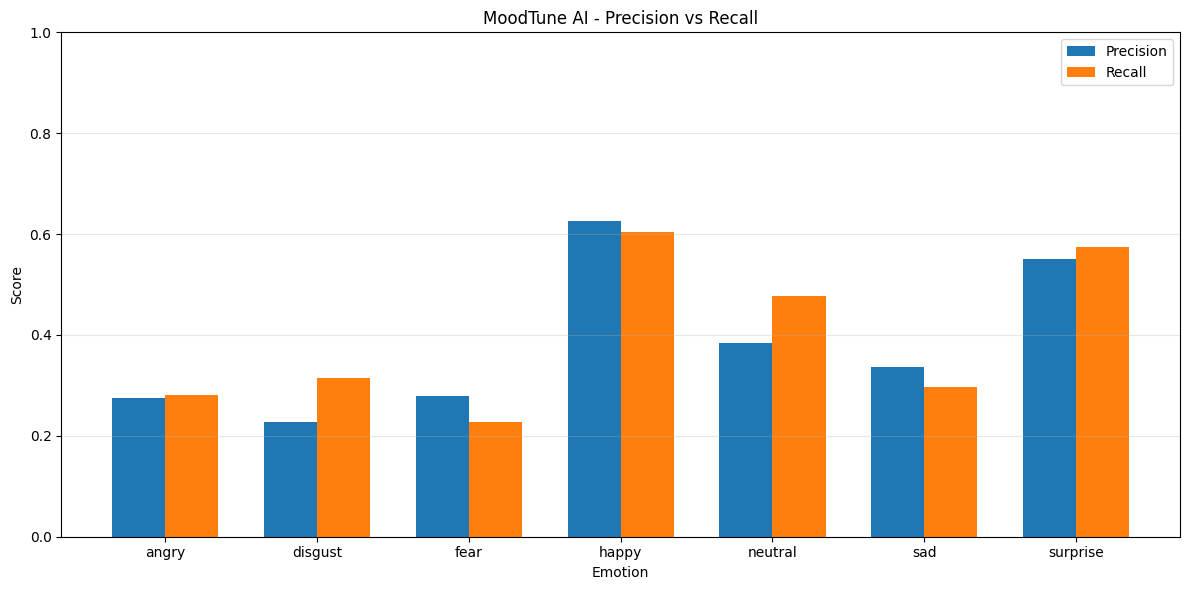

In [ ]:

# ==========================================
# CELL 5: Precision vs Recall
# ==========================================

x = np.arange(len(class_names))
width = 0.35

plt.figure(figsize=(12, 6))

plt.bar(
    x - width/2,
    emotion_results["Precision"],
    width,
    label="Precision"
)

plt.bar(
    x + width/2,
    emotion_results["Recall"],
    width,
    label="Recall"
)

plt.xticks(x, class_names)

plt.ylabel("Score")
plt.xlabel("Emotion")

plt.title(
    "MoodTune AI - Precision vs Recall"
)

plt.ylim(0, 1)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


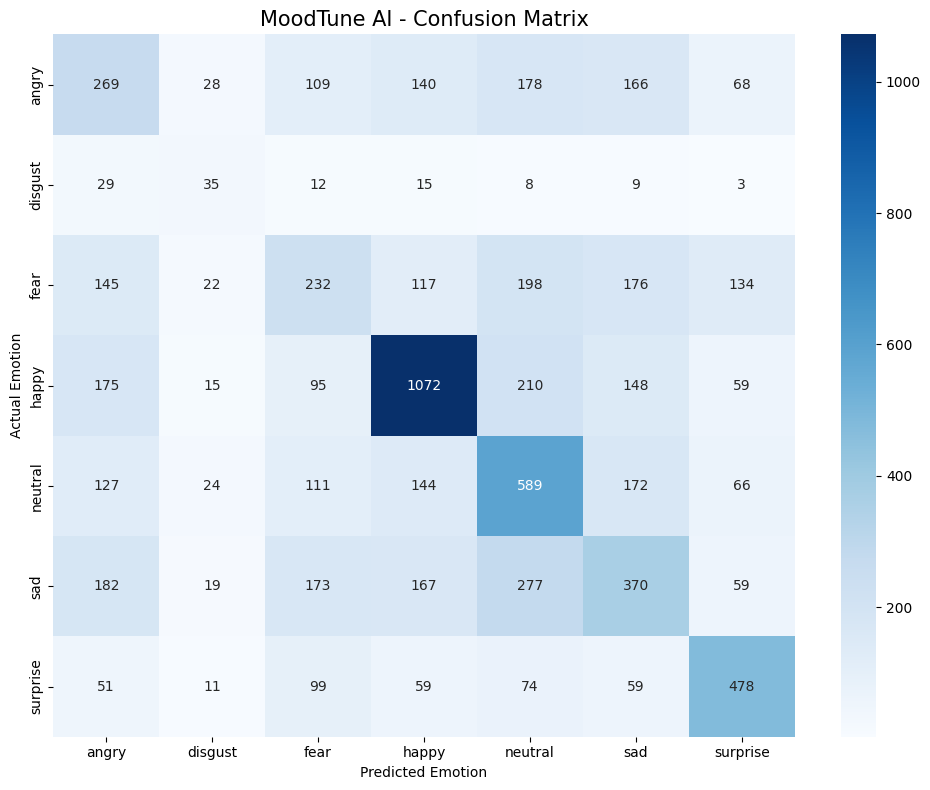

In [ ]:

# ==========================================
# CELL 6: Confusion Matrix
# ==========================================

cm = confusion_matrix(
    y_test_analysis,
    y_pred_analysis,
    labels=list(range(len(class_names)))
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title(
    "MoodTune AI - Confusion Matrix",
    fontsize=15
)

plt.xlabel("Predicted Emotion")
plt.ylabel("Actual Emotion")

plt.tight_layout()
plt.show()


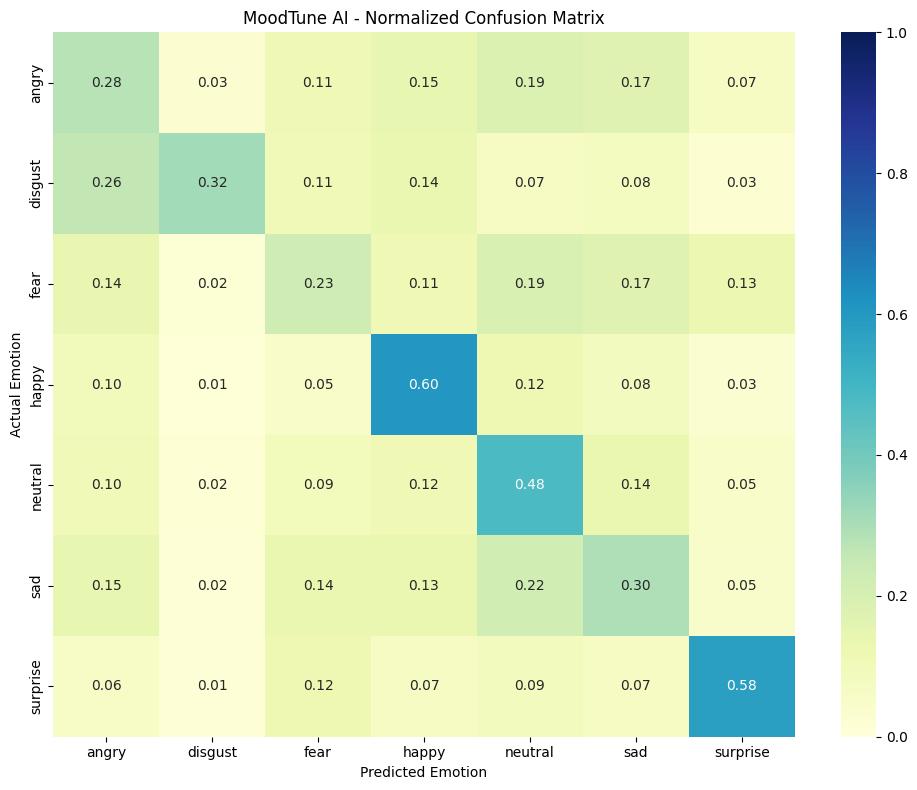

In [ ]:

# ==========================================
# CELL 7: Normalized Confusion Matrix
# ==========================================

cm_normalized = (
    cm.astype("float") /
    np.maximum(cm.sum(axis=1, keepdims=True), 1)
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm_normalized,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    xticklabels=class_names,
    yticklabels=class_names,
    vmin=0,
    vmax=1
)

plt.title(
    "MoodTune AI - Normalized Confusion Matrix"
)

plt.xlabel("Predicted Emotion")
plt.ylabel("Actual Emotion")

plt.tight_layout()
plt.show()


In [ ]:

# ==========================================
# CELL 8: Most Confused Emotion Pairs
# ==========================================

confusion_pairs = []

for i in range(len(class_names)):
    for j in range(len(class_names)):

        if i != j and cm[i, j] > 0:

            confusion_pairs.append({
                "Actual Emotion": class_names[i],
                "Predicted Emotion": class_names[j],
                "Wrong Predictions": int(cm[i, j])
            })

confusion_df = pd.DataFrame(confusion_pairs)

confusion_df = confusion_df.sort_values(
    by="Wrong Predictions",
    ascending=False
).reset_index(drop=True)

print("===== TOP 10 CONFUSED EMOTION PAIRS =====")

display(confusion_df.head(10))


===== TOP 10 CONFUSED EMOTION PAIRS =====


,Actual Emotion,Predicted Emotion,Wrong Predictions
0,sad,neutral,277
1,happy,neutral,210
2,fear,neutral,198
3,sad,angry,182
4,angry,neutral,178
5,fear,sad,176
6,happy,angry,175
7,sad,fear,173
8,neutral,sad,172
9,sad,happy,167


Total incorrect predictions: 4133
Total test images: 7178
Error rate: 57.58 %


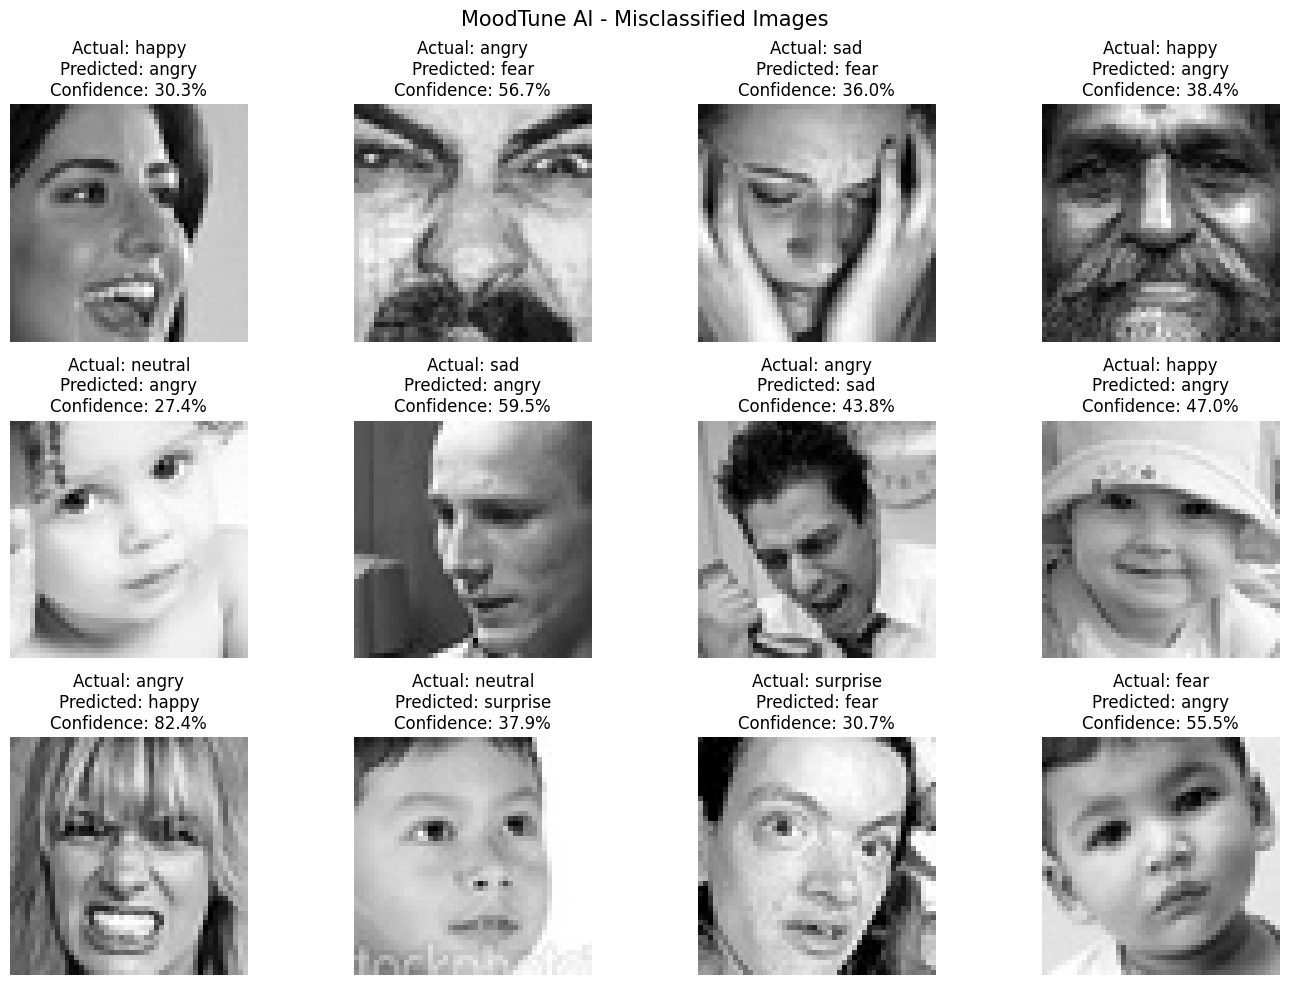

In [ ]:

# ==========================================
# CELL 9: Misclassified Image Analysis
# ==========================================

wrong_indices = np.where(
    y_test_analysis != y_pred_analysis
)[0]

print("Total incorrect predictions:", len(wrong_indices))
print("Total test images:", len(y_test_analysis))

print(
    "Error rate:",
    round(len(wrong_indices) / len(y_test_analysis) * 100, 2),
    "%"
)

if len(wrong_indices) > 0:

    sample_size = min(12, len(wrong_indices))

    rng = np.random.default_rng(42)

    selected_indices = rng.choice(
        wrong_indices,
        sample_size,
        replace=False
    )

    fig, axes = plt.subplots(
        3, 4, figsize=(14, 10)
    )

    for ax in axes.flat:
        ax.axis("off")

    for ax, idx in zip(axes.flat, selected_indices):

        image = X_test_analysis[idx].squeeze()

        ax.imshow(image, cmap="gray")

        true_emotion = class_names[
            y_test_analysis[idx]
        ]

        predicted_emotion = class_names[
            y_pred_analysis[idx]
        ]

        confidence = np.max(y_prob[idx]) * 100

        ax.set_title(
            f"Actual: {true_emotion}\n"
            f"Predicted: {predicted_emotion}\n"
            f"Confidence: {confidence:.1f}%"
        )

    plt.suptitle(
        "MoodTune AI - Misclassified Images",
        fontsize=15
    )

    plt.tight_layout()
    plt.show()


In [ ]:

# ==========================================
# CELL 10: Save Emotion Analysis Results
# ==========================================

import os

ANALYSIS_DIR = (
    "/content/drive/MyDrive/"
    "MoodTune_AI_Results/reports/emotion_analysis"
)

os.makedirs(
    ANALYSIS_DIR,
    exist_ok=True
)

# Save emotion performance
emotion_results.to_csv(
    os.path.join(
        ANALYSIS_DIR,
        "emotion_performance.csv"
    ),
    index=False
)

# Save confusion matrix
pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
).to_csv(
    os.path.join(
        ANALYSIS_DIR,
        "confusion_matrix.csv"
    )
)

# Save normalized confusion matrix
pd.DataFrame(
    cm_normalized,
    index=class_names,
    columns=class_names
).to_csv(
    os.path.join(
        ANALYSIS_DIR,
        "normalized_confusion_matrix.csv"
    )
)

# Save confused emotion pairs
confusion_df.to_csv(
    os.path.join(
        ANALYSIS_DIR,
        "confused_emotion_pairs.csv"
    ),
    index=False
)

print("Emotion analysis saved successfully!")

print("\nSaved location:")
print(ANALYSIS_DIR)

print("\nSaved files:")
for filename in os.listdir(ANALYSIS_DIR):
    print("-", filename)


Emotion analysis saved successfully!

Saved location:
/content/drive/MyDrive/MoodTune_AI_Results/reports/emotion_analysis

Saved files:
- emotion_performance.csv
- confusion_matrix.csv
- normalized_confusion_matrix.csv
- confused_emotion_pairs.csv


In [ ]:

# ==========================================
# MOODTUNE AI
# STEP 1: Check Existing Model Files
# NO TRAINING
# ==========================================

from google.colab import drive
import os

# Connect Google Drive
if not os.path.exists("/content/drive/MyDrive"):
    drive.mount("/content/drive")
else:
    print("Google Drive is already connected.")

# Model directory
MODEL_DIR = (
    "/content/drive/MyDrive/"
    "MoodTune_AI_Results/models"
)

print("=" * 50)
print("MOODTUNE AI - EXISTING MODEL CHECK")
print("=" * 50)

required_files = [
    "emotion_model.keras",
    "baseline_cnn.keras",
    "improved_cnn.keras",
    "class_names.json"
]

for filename in required_files:

    path = os.path.join(MODEL_DIR, filename)

    if os.path.exists(path):

        size_mb = os.path.getsize(path) / (1024 * 1024)

        print(f"[FOUND] {filename}")
        print(f"        Size: {size_mb:.2f} MB")

    else:
        print(f"[MISSING] {filename}")

print("\nModel verification completed.")


Google Drive is already connected.
MOODTUNE AI - EXISTING MODEL CHECK
[FOUND] emotion_model.keras
        Size: 13.77 MB
[FOUND] baseline_cnn.keras
        Size: 13.77 MB
[FOUND] improved_cnn.keras
        Size: 1.89 MB
[FOUND] class_names.json
        Size: 0.00 MB

Model verification completed.


In [ ]:

# ==========================================
# MOODTUNE AI
# STEP 2: Load Existing Model
# NO TRAINING
# ==========================================

import tensorflow as tf
import numpy as np
import json
import os

MODEL_PATH = (
    "/content/drive/MyDrive/"
    "MoodTune_AI_Results/models/emotion_model.keras"
)

CLASS_PATH = (
    "/content/drive/MyDrive/"
    "MoodTune_AI_Results/models/class_names.json"
)

# Load existing model
model = tf.keras.models.load_model(MODEL_PATH)

# Load emotion classes
with open(CLASS_PATH, "r", encoding="utf-8") as f:
    class_names = json.load(f)

print("=" * 50)
print("MOODTUNE AI - MODEL VERIFICATION")
print("=" * 50)

print("\nModel loaded successfully!")
print("Model name:", model.name)
print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)

print("\nEmotion classes:")
for i, emotion in enumerate(class_names):
    print(i, "-", emotion)

# Check output classes
assert model.output_shape[-1] == len(class_names), (
    "Output classes do not match class_names!"
)

# Dummy inference only (no training)
dummy_image = np.zeros(
    (1, 48, 48, 1),
    dtype=np.float32
)

prediction = model.predict(
    dummy_image,
    verbose=0
)

print("\nTest inference completed!")
print("Prediction shape:", prediction.shape)
print("Predicted emotion:",
      class_names[np.argmax(prediction[0])])

print("\nMODEL READY FOR APPLICATION!")


MOODTUNE AI - MODEL VERIFICATION

Model loaded successfully!
Model name: baseline_cnn
Input shape: (None, 48, 48, 1)
Output shape: (None, 7)

Emotion classes:
0 - angry
1 - disgust
2 - fear
3 - happy
4 - neutral
5 - sad
6 - surprise

Test inference completed!
Prediction shape: (1, 7)
Predicted emotion: angry

MODEL READY FOR APPLICATION!


In [ ]:

# ==========================================
# STEP 3: Check Original Data Preprocessing
# NO TRAINING
# ==========================================

print("===== ORIGINAL TRAINING DATA =====")

print("X_train minimum:", np.min(X_train))
print("X_train maximum:", np.max(X_train))
print("X_train mean:", np.mean(X_train))

print("\n===== MODEL INFORMATION =====")

model.summary()

print("\n===== CLASS INFORMATION =====")

print(class_names)

print("\nPreprocessing check completed!")


===== ORIGINAL TRAINING DATA =====
X_train minimum: 0.0
X_train maximum: 1.0
X_train mean: 0.50886625

===== MODEL INFORMATION =====


Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 48, 48, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,179,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,598,487 (13.73 MB)

 Trainable params: 1,199,495 (4.58 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2,398,992 (9.15 MB)


===== CLASS INFORMATION =====
['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']

Preprocessing check completed!


In [ ]:

# ==========================================
# MOODTUNE AI
# STEP 4: Create Application Folder
# NO TRAINING
# ==========================================

import os
import shutil

PROJECT_DIR = "/content/MoodTune_AI"

os.makedirs(PROJECT_DIR, exist_ok=True)

# Copy existing trained model
shutil.copy2(
    "/content/drive/MyDrive/MoodTune_AI_Results/models/emotion_model.keras",
    os.path.join(PROJECT_DIR, "emotion_model.keras")
)

# Copy emotion class names
shutil.copy2(
    "/content/drive/MyDrive/MoodTune_AI_Results/models/class_names.json",
    os.path.join(PROJECT_DIR, "class_names.json")
)

print("Project folder created!")

print("\nProject files:")
for filename in os.listdir(PROJECT_DIR):
    path = os.path.join(PROJECT_DIR, filename)
    print(filename, "-", round(os.path.getsize(path) / (1024 * 1024), 2), "MB")


Project folder created!

Project files:
emotion_model.keras - 13.77 MB
class_names.json - 0.0 MB


In [ ]:

# ==========================================
# STEP 5: Create requirements.txt
# ==========================================

requirements = """
streamlit
tensorflow
numpy
pandas
Pillow
opencv-python-headless
"""

with open(
    os.path.join(PROJECT_DIR, "requirements.txt"),
    "w"
) as f:
    f.write(requirements.strip() + "\n")

print("requirements.txt created!")
print(requirements)


requirements.txt created!

streamlit
tensorflow
numpy
pandas
Pillow
opencv-python-headless



In [ ]:

%%writefile /content/MoodTune_AI/app.py

import os
import json
import cv2
import numpy as np
import streamlit as st

from PIL import Image
from tensorflow import keras

# ==========================================
# PAGE CONFIGURATION
# ==========================================

st.set_page_config(
    page_title="MoodTune AI",
    page_icon="😊",
    layout="wide"
)

# ==========================================
# EMOTION INFORMATION
# ==========================================

EMOTIONS = {
    "angry": "Angry",
    "disgust": "Disgust",
    "fear": "Fear",
    "happy": "Happy",
    "neutral": "Neutral",
    "sad": "Sad",
    "surprise": "Surprise"
}

# ==========================================
# LOAD EXISTING TRAINED MODEL
# ==========================================

BASE_DIR = os.path.dirname(os.path.abspath(__file__))

MODEL_PATH = os.path.join(
    BASE_DIR,
    "emotion_model.keras"
)

CLASS_PATH = os.path.join(
    BASE_DIR,
    "class_names.json"
)


@st.cache_resource
def load_emotion_model():

    model = keras.models.load_model(
        MODEL_PATH,
        compile=False
    )

    with open(CLASS_PATH, "r", encoding="utf-8") as f:
        class_names = json.load(f)

    if model.input_shape != (None, 48, 48, 1):
        raise ValueError("Unexpected model input shape.")

    if model.output_shape[-1] != len(class_names):
        raise ValueError("Model output and class names mismatch.")

    return model, class_names


try:
    model, class_names = load_emotion_model()
except Exception as e:
    st.error(f"Model loading failed: {e}")
    st.stop()


# ==========================================
# FACE DETECTION
# ==========================================

@st.cache_resource
def load_face_detector():

    cascade_path = os.path.join(
        cv2.data.haarcascades,
        "haarcascade_frontalface_default.xml"
    )

    detector = cv2.CascadeClassifier(cascade_path)

    if detector.empty():
        raise RuntimeError("Face detector could not be loaded.")

    return detector


# ==========================================
# IMAGE PREPROCESSING
# ==========================================

def preprocess_image(image):

    image_array = np.array(image.convert("RGB"))

    gray = cv2.cvtColor(
        image_array,
        cv2.COLOR_RGB2GRAY
    )

    detector = load_face_detector()

    faces = detector.detectMultiScale(
        gray,
        scaleFactor=1.1,
        minNeighbors=5,
        minSize=(30, 30)
    )

    if len(faces) == 0:
        return None, None

    # Select largest detected face
    x, y, w, h = max(
        faces,
        key=lambda face: face[2] * face[3]
    )

    face = gray[y:y+h, x:x+w]

    face_resized = cv2.resize(
        face,
        (48, 48),
        interpolation=cv2.INTER_AREA
    )

    # Same normalization as training
    face_normalized = (
        face_resized.astype("float32") / 255.0
    )

    # Model input: (1, 48, 48, 1)
    model_input = np.expand_dims(
        face_normalized,
        axis=(0, -1)
    )

    return model_input, face_resized


# ==========================================
# USER INTERFACE
# ==========================================

st.title("😊 MoodTune AI")

st.subheader(
    "AI-Based Facial Emotion Recognition"
)

st.write(
    "Upload a face image and let MoodTune AI "
    "analyze its facial expression."
)

st.info(
    "This application uses a CNN model trained "
    "specifically for seven facial expression classes."
)

st.caption(
    "Predictions represent model classifications, "
    "not a definitive measurement of a person's feelings."
)

# ==========================================
# IMAGE UPLOAD
# ==========================================

uploaded_file = st.file_uploader(
    "Upload a face image",
    type=["jpg", "jpeg", "png"]
)

if uploaded_file is not None:

    try:

        image = Image.open(uploaded_file).convert("RGB")

        col1, col2 = st.columns(2)

        with col1:
            st.image(
                image,
                caption="Uploaded Image",
                use_container_width=True
            )

        model_input, processed_face = preprocess_image(image)

        if model_input is None:

            st.warning(
                "No face detected. Please upload a clear, "
                "front-facing face image."
            )

        else:

            with col2:
                st.image(
                    processed_face,
                    caption="Processed Face (48 x 48)",
                    clamp=True,
                    use_container_width=True
                )

            # ==================================
            # PREDICTION
            # ==================================

            with st.spinner("Analyzing facial expression..."):

                probabilities = model.predict(
                    model_input,
                    verbose=0
                )[0]

            predicted_index = int(np.argmax(probabilities))

            predicted_emotion = class_names[predicted_index]

            confidence = float(
                probabilities[predicted_index] * 100
            )

            st.divider()

            st.subheader("Prediction Result")

            st.success(
                f"Predicted Expression: "
                f"{EMOTIONS.get(predicted_emotion, predicted_emotion.title())}"
            )

            st.metric(
                "Model Confidence",
                f"{confidence:.2f}%"
            )

            # ==================================
            # ALL EMOTION PROBABILITIES
            # ==================================

            st.subheader("Emotion Probability Distribution")

            for i, emotion in enumerate(class_names):

                probability = float(probabilities[i])

                st.write(
                    f"**{EMOTIONS.get(emotion, emotion.title())}** "
                    f"- {probability * 100:.2f}%"
                )

                st.progress(
                    min(max(probability, 0.0), 1.0)
                )

            st.caption(
                "Probabilities are model output scores, "
                "not calibrated measures of actual emotion."
            )

    except Exception as e:

        st.error(
            f"Unable to process this image: {e}"
        )

st.divider()

st.caption(
    "MoodTune AI | Machine Learning Final Project"
)

st.caption(
    "Model: Baseline CNN | Input: 48x48 Grayscale"
)


Writing /content/MoodTune_AI/app.py


In [ ]:

# ==========================================
# STEP 7: Verify and Package Application
# NO TRAINING
# ==========================================

import os
import zipfile

print("===== PROJECT FILE CHECK =====")

required_files = [
    "app.py",
    "requirements.txt",
    "emotion_model.keras",
    "class_names.json"
]

for filename in required_files:

    path = os.path.join(PROJECT_DIR, filename)

    if os.path.exists(path):
        print("[OK]", filename)
    else:
        raise FileNotFoundError(
            f"Missing file: {filename}"
        )

# Create ZIP
ZIP_PATH = "/content/MoodTune_AI.zip"

with zipfile.ZipFile(
    ZIP_PATH,
    "w",
    zipfile.ZIP_DEFLATED
) as zipf:

    for filename in required_files:

        file_path = os.path.join(
            PROJECT_DIR,
            filename
        )

        zipf.write(
            file_path,
            arcname=filename
        )

print("\nApplication package created!")

print("ZIP:", ZIP_PATH)

print(
    "ZIP size:",
    round(os.path.getsize(ZIP_PATH) / (1024 * 1024), 2),
    "MB"
)


===== PROJECT FILE CHECK =====
[OK] app.py
[OK] requirements.txt
[OK] emotion_model.keras
[OK] class_names.json

Application package created!
ZIP: /content/MoodTune_AI.zip
ZIP size: 9.77 MB


In [ ]:
from google.colab import files
files.download("/content/MoodTune_AI.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>